1. What is the most important factor in determining whether a person was likely to survive the sinking of the Titanic

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
sns.set_style('whitegrid')


titanic_df = pd.read_csv('titanic.csv')


Working with missing data. Taking a first look at the data we can see missing values in the Cabin column. Let us start by checking the dimensions of the DataFrame to understand its size and preview the first few rows to get a sense of the data


In [2]:
# Return the number of rows and columns of the DataFrame
titanic_df.shape

(891, 12)

In [3]:
titanic_df.head()
titanic_df.info()
titanic_df.describe(include='all').T

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


How many NaN values can be identified? Now that we have seen that there are values, we need to get a sense of how many missing values exist in the whole dataset. We need to find how many missing values are there in each column

In [4]:
# Get the number of missing data values per column
missing_values_count = titanic_df.isnull().sum()

# let us look at the number of missing values in the twelve columns
missing_values_count[0:12]

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

To better understant how much data is missing, we can calculate the percentage of all missing values. If we get a very high percentage, we may be unable to use the data

In [5]:
# Total number of missing values
total_cells = np.prod(titanic_df.shape)
total_missing = missing_values_count.sum()

# Percent of data that is missing
(total_missing/total_cells) * 100

np.float64(8.099513655069211)

Only 8% of values are missing

Survival distribution

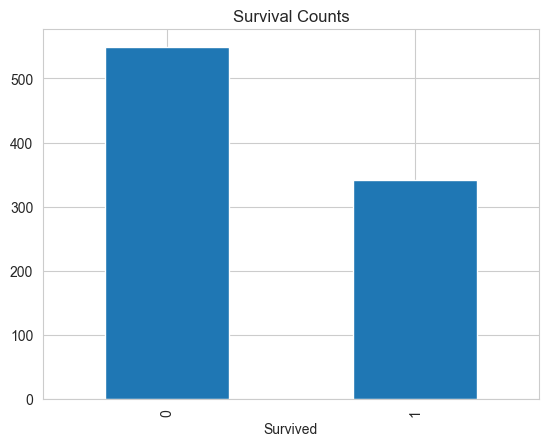

In [6]:
titanic_df['Survived'].value_counts().plot(kind='bar')
plt.title('Survival Counts')
plt.show()

Survival by Sex

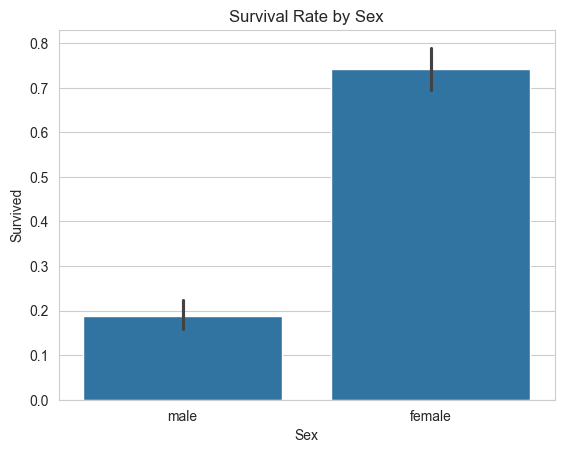

In [7]:
sns.barplot(data=titanic_df,x='Sex',y='Survived')
plt.title('Survival Rate by Sex')
plt.show()

Survival by class

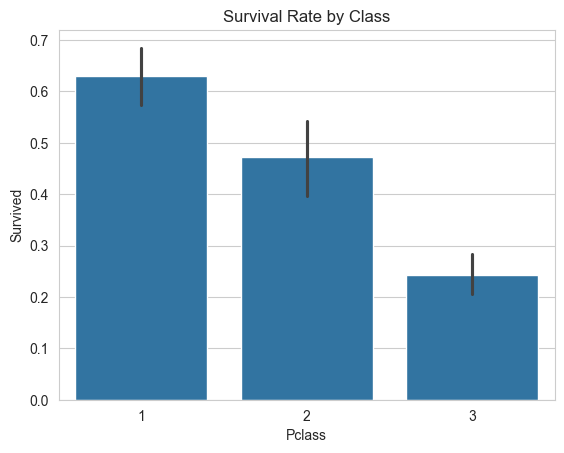

In [8]:
sns.barplot(data=titanic_df,x='Pclass',y='Survived')
plt.title('Survival Rate by Class')
plt.show()

Survival by Age

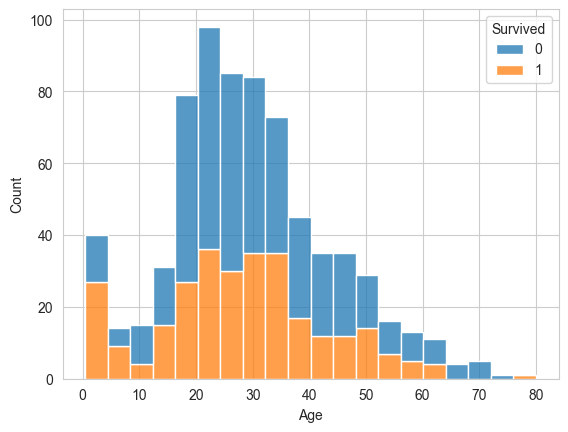

In [9]:
sns.histplot(data=titanic_df,x='Age',hue='Survived',multiple='stack')
plt.show()

Children and women priority

Sex     Child
female  False    0.756458
        True     0.651163
male    False    0.163873
        True     0.525000
Name: Survived, dtype: float64


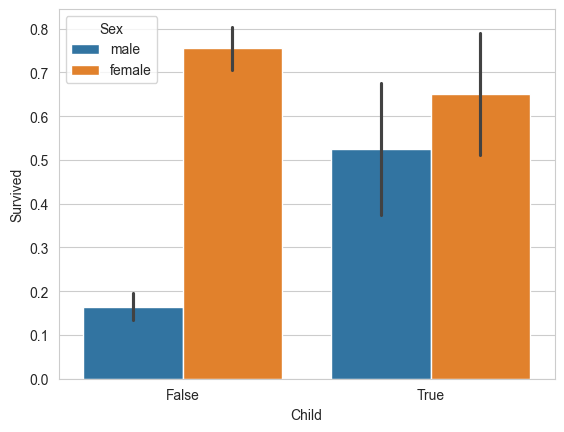

In [10]:
titanic_df['Child']=titanic_df['Age']<16
print(titanic_df.groupby(['Sex','Child'])['Survived'].mean())
sns.barplot(data=titanic_df,x='Child',y='Survived',hue='Sex')
plt.show()

Correlation or feature importance

In [11]:
tmp=titanic_df.copy()
tmp['Sex']=tmp['Sex'].map({'male':0,'female':1})
print(tmp[['Survived','Pclass','Sex','Age','SibSp','Parch','Fare']].corr()['Survived'].sort_values(ascending=False))

Survived    1.000000
Sex         0.543351
Fare        0.257307
Parch       0.081629
SibSp      -0.035322
Age        -0.077221
Pclass     -0.338481
Name: Survived, dtype: float64


From the analysis and graphs, **Sex** was the strongest means of survival, followed by passenger class.

Higher-class (1st class) passengers had a higher survival rates than 2nd and 3rd class passengers, supporting the idea that upper-class passengers were given preference.

The data generally supports the **'women and children first'** preferences. Females and children had a higher survival rates than adult males.

Passengers who paid higher fares generally had better survival rates, because a higher fare is associated with higher passenger class and cabin location.